# Rebuilding Doug: an introduction to PCA

How much detail do we need to recognize a face?


We will load a photo and rebuild it using fewer pieces of information.




## 1. Setup: load our tools

NumPy helps us work with numbers. Matplotlib helps us load and display images.

Other libraries to read the image from the repo url.

In [ ]:
# Load tools for working with numbers and images.
import numpy as np
import matplotlib.pyplot as plt

# The following libraries are used to read the image url
import requests
from PIL import Image
from io import BytesIO

## 2. Data ingestion: load the image

**Data ingestion** means loading data into Python. Our data is a photo.

A photo is made of tiny dots called **pixels**. Each pixel has numbers for red, green, and blue (RGB). Python reads these numbers into an **array**, which stores them together.

In [ ]:
url = (
    "https://raw.githubusercontent.com/CharleyHananiaGA/"
    "DSB-Unit-03/main/27%20-%20Principal%20Component%20Analysis%20%28PCA%29/"
    "make-doug/doug.jpg"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

# Load the photo as numbers for red, green, and blue.
doug = np.array(Image.open(BytesIO(response.content)).convert("RGB"))
doug.shape

(900, 900, 3)

## 3. Explore: look at the image

First, display the photo. Then check how many rows of pixels it has. This tells us its height.

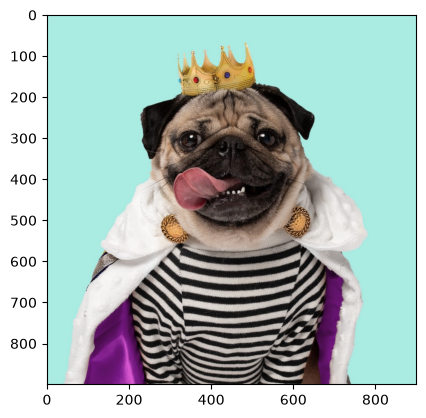

In [ ]:
# Show the original color photo.
plt.imshow(doug)

In [ ]:
# Let's see how the values of doug look like
doug[100][500:505]

array([[168, 235, 228],
       [168, 235, 226],
       [169, 237, 226],
       [169, 237, 226],
       [170, 235, 227]], dtype=uint8)

## 4. Preprocessing: prepare the image

**Preprocessing** means preparing data before using it.

We turn the photo into **grayscale**, or shades of gray. We average each pixel's red, green, and blue numbers. This gives us one brightness number per pixel.

The result is a **matrix**: a grid of numbers arranged in rows and columns.

We also divide by 255. This puts brightness between 0 (black) and 1 (white).
Changing values to a shared scale is called **normalization** and can be done
with MinMaxScaler from Scikit-learn.

To repeat this step, reload the photo first.

In [ ]:
# Average the three colors and put brightness on a scale from 0 to 1.
doug = np.mean(doug, axis=2) / 255.0

# Check the number of rows and columns.
doug.shape

(900, 900)

## 5. Save the grayscale image

Display and save the image before removing any patterns. We will use it to compare the results.

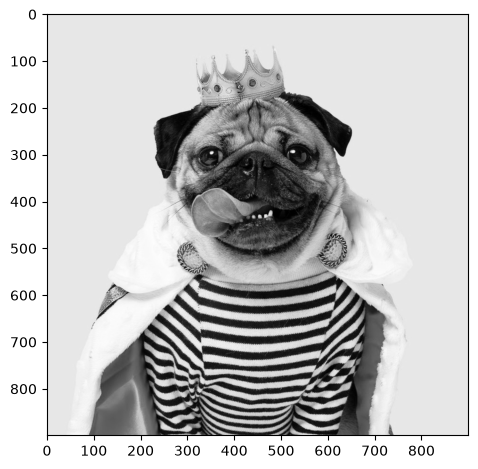

In [ ]:
# Show the grayscale image. Use 1 - doug to keep bright areas bright.
plt.imshow(1 - doug, cmap='Greys')
# Adjust the spacing and save the plot.
plt.tight_layout()
plt.savefig('doug-full.png')

## 6. Principal component analysis (PCA): keep the main patterns

**Principal component analysis (PCA)** helps summarize data with fewer patterns. These patterns are called **components**. PCA keeps the patterns that explain the biggest differences in the data.

Here we use a related tool: **singular value decomposition (SVD)**. It breaks our image into patterns we can put back together. Keeping fewer patterns gives us a simpler image.

SVD is also used to calculate PCA. This example shows the idea behind PCA. It is not the full PCA process. Standard PCA first subtracts each column's average. We skip that step here.

The code returns three results:

- `u` and `vh` hold the image patterns.
- `s` holds their strengths, called **singular values**. The largest comes first.

Later, `k` will tell us how many patterns to keep.

In [ ]:
# Use SVD to find image patterns and their strengths.
u, s, vh = np.linalg.svd(doug)

## 7. Reconstruction: rebuild the image

**Reconstruction** means putting the image back together.

We create a **function** so we can reuse the same steps. It takes three inputs:

- `ax`: where to draw the image.
- `k`: how many components to keep.
- `t`: the plot title.

The function keeps the first `k` components and combines them. The image keeps its original height and width. With fewer components, it loses detail.

In [ ]:
# This part to make out plots look nice. You don't need to understand
# this part, focus on PCA and what it does to the image !

# Create a reusable function to rebuild the image with k components.

def plot_doug(ax, k, t):
    # Select the first k patterns and combine them with @.
    ax.imshow(1 - u[:, :k] @ np.diag(s)[:k, :k] @ vh[:k, :], cmap='Greys')
    # Add a title to this plot.
    ax.set_title(t)

### Try 75 components

Rebuild the image using 75 components. Can you still recognize Doug? Compare it with the grayscale image above.

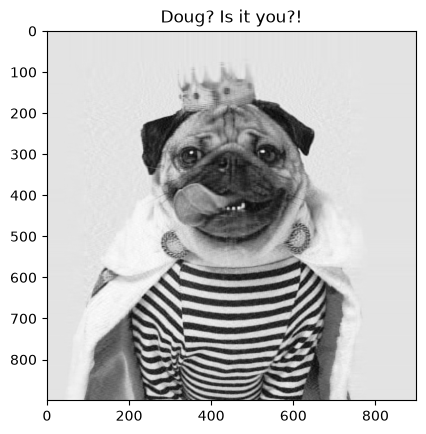

In [ ]:
# Draw the image using the first 75 components.
fig, ax = plt.subplots(1, 1)
plot_doug(ax, 75, 'Doug? Is it you?!')

## 8. Now back to you ! Compare: how many components are enough?

This image has 900 rows and 900 columns. Using `k = 900` keeps all its components.

What happens to the details as we keep fewer components. Choose some numbers and
try for yourself !

In [ ]:
# Define five numbers of components to try for rebuilding the image.
# Type the numbers in the list below, and ensure they are separated by commas.
ks = [
    ,
    ,
    ,
    ,

      ]

SyntaxError: invalid syntax (1926412898.py, line 4)

In [ ]:
# Compare six choices of k in a grid of plots.
fig, axs = plt.subplots(2, 3, figsize=(20, 12))

# Execute the followign line inside a try statement to avoid an error if the
# list ks is not populated with five numbers. If the list is not populated, the code will
# still run, but the last two plots will be empty.
try:
    plot_doug(axs[0][0], 900, 'Full image ($k = 900$)')
    plot_doug(axs[0][1], 100, f'$k = {ks[0]}$')
    plot_doug(axs[0][2], 50, f'$k = {ks[1]}$')
    plot_doug(axs[1][0], 20, f'$k = {ks[2]}$')
    plot_doug(axs[1][1], 10, f'$k = {ks[3]}$')
    plot_doug(axs[1][2], 5, f'$k = {ks[4]}$')
    # Adjust the spacing and save the comparison.
    plt.tight_layout()
    plt.savefig('doug-pca.png')
except IndexError:
    print("The list 'ks' does not contain enough elements. Please ensure it has at least five numbers.")


## 9. Think about what you see

- When does Doug's face become hard to recognize?
- What disappears first: small details or large shapes?
- Why does the rebuilt image stay gray, even with all 900 components?

Try a different whole number from 1 to 900 in the 75-component example. Run that cell again to see the result.